# Solving the Traveling Salesman  Problem using Local Search

Points: 10

## The [Traveling Salesman Problem](https://en.wikipedia.org/wiki/Travelling_salesman_problem)

* __Goal:__ Find the shortest tour visiting each of $n$ cities exactly once and returning back to the starting city. Given are pairwise distances between cities, where $d_{i,j}$ is the distance from city $i$ to city $j$. 

* __State space:__ Each state represents a tour. The cities are numbered and a tour can be expressed as vector  $\pi$ with the order in which the cities are visited (a [permutation](https://en.wikipedia.org/wiki/Permutation)). That is, $\pi(1)$ is the index of the first city to visit, $\pi(2)$ the index of the second, and so on.

* __Objective function:__ Minimize the tour length. The optimization problem is to find the optimal tour $\pi^*$ through the $n$ cities and returning to the starting city:

  > minimize: $\mathrm{tourlength}(\pi) = d_{\pi(n),\pi(1)} + \sum_{i = 1}^{n-1} d_{\pi(i),\pi(i+1)}$
  > 
  > subject to: $\pi \ \text{is a valid permutation vector}$

* __Local moves:__ Exchange two cities in the order.

## Helper functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import random

np.set_printoptions(precision=2)
pd.set_option('display.precision', 2)

# make the results repeatable
np.random.seed(1234)

In [2]:
def random_tour(n):
    """Create a random tour"""
    
    tour = list(range(n))
    random.shuffle(tour)
    return(tour)

random_tour(10)

[0, 4, 5, 7, 3, 1, 6, 9, 8, 2]

In [3]:
from scipy.spatial.distance import pdist
from scipy.spatial.distance import squareform

def random_tsp(n):
    """
    Create a random (Euclidean) traveling salesman problem. Choose n points randomly in a 1 x 1 unit square and calulates a 
    pairwise Euclidean distance matrix.
    """
    
    pos = pd.DataFrame({
        "x" : np.random.uniform(size = n),
        "y" : np.random.uniform(size = n)
    })
    
    dist = squareform(pdist(pos))
    
    return({"pos": pos, "dist": dist})
    
tsp = random_tsp(10)

print(f"Positions:\n{tsp['pos']}")
print(f"Distance matrix:\n{pd.DataFrame(tsp['dist'])})")

Positions:
      x     y
0  0.19  0.36
1  0.62  0.50
2  0.44  0.68
3  0.79  0.71
4  0.78  0.37
5  0.27  0.56
6  0.28  0.50
7  0.80  0.01
8  0.96  0.77
9  0.88  0.88
Distance matrix:
      0     1     2     3     4     5     6     7     8     9
0  0.00  0.45  0.41  0.69  0.59  0.22  0.17  0.70  0.87  0.86
1  0.45  0.00  0.26  0.27  0.20  0.35  0.35  0.52  0.43  0.46
2  0.41  0.26  0.00  0.35  0.46  0.21  0.24  0.76  0.53  0.48
3  0.69  0.27  0.35  0.00  0.34  0.53  0.55  0.70  0.18  0.19
4  0.59  0.20  0.46  0.34  0.00  0.54  0.52  0.36  0.44  0.52
5  0.22  0.35  0.21  0.53  0.54  0.00  0.06  0.76  0.72  0.68
6  0.17  0.35  0.24  0.55  0.52  0.06  0.00  0.72  0.73  0.71
7  0.70  0.52  0.76  0.70  0.36  0.76  0.72  0.00  0.77  0.87
8  0.87  0.43  0.53  0.18  0.44  0.72  0.73  0.77  0.00  0.14
9  0.86  0.46  0.48  0.19  0.52  0.68  0.71  0.87  0.14  0.00)


In [4]:
def tour_length(tsp, tour):
    """Caclulate the length of a tour, i.e., the objective function."""
    
    # make sure tour is a Python list (not an array or a numpy.array)
    if not isinstance(tour, list): tour = tour.tolist()
    
    tl = 0
    dist = tsp["dist"]
    
    for i in range(len(tour)-1):
        tl += dist[tour[i], tour[i+1]]
    
    tl += dist[tour[-1], tour[0]]
    
    return(tl)
        
tour = random_tour(10)
tour_length(tsp, tour)

np.float64(5.879561154520054)

Tour length: 5.88


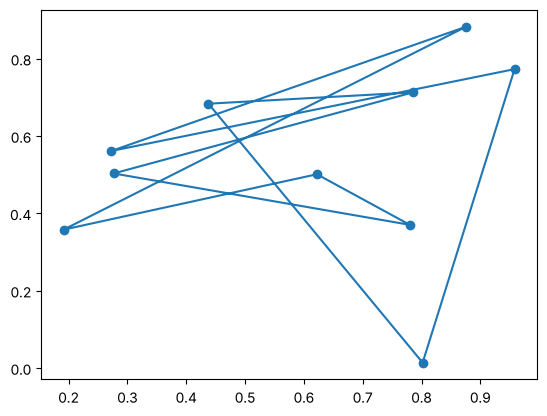

In [5]:
def show_tsp(tsp, tour = None):  
    """display the traveling salesman problem and a tour."""
    
    pos = tsp["pos"]
    
    plt.scatter(pos["x"], pos["y"])
    
    if tour is not None:
        # make sure tour is a Python list (not an array or a numpy.array)
        if not isinstance(tour, list): tour = tour.tolist()
        
        print(f"Tour length: {round(tour_length(tsp, tour), 2)}")
        
        pos_ = pos.reindex(tour)
        pos_ = pd.concat([pos_, pos_.head(1)])
        plt.plot(pos_["x"], pos_["y"])
    
    plt.show()
    
show_tsp(tsp, tour)

## Steepest-ascend Hill Climbing Search [3 Points]

Calculate the objective function for all local moves (move each queen within its column) and always choose the best among all local moves.

**Cài đặt.** Trạng thái là một hoán vị `tour` của các thành phố. **Lân cận (toán tử cục bộ):** hoán đổi hai thành phố ở vị trí $i < j$ trong tour; một tour $n$ thành phố có $n(n-1)/2$ lân cận. Toán tử này được dùng *thống nhất* cho mọi thuật toán so sánh bên dưới (riêng phần cuối có so sánh thêm toán tử đảo đoạn 2-opt). Hàm mục tiêu là `tour_length` (cần *cực tiểu hóa*).

Mỗi thuật toán trả về dict: `tour`, `length`, `steps` (số nước đi được nhận), `evals` (số lần gọi `tour_length`) và `history` (độ dài tour theo từng bước/lần thử).

Tour ban đầu: 11.337  ->  sau steepest-ascent: 4.763 (10 bước, 2090 lần đánh giá)
Tour length: 4.76


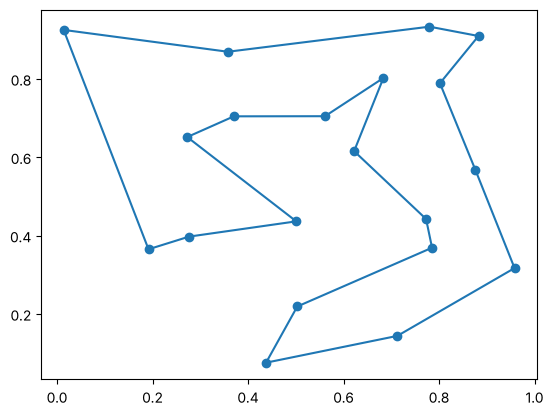

In [6]:
def swap_cities(tour, i, j):
    """Lân cận kiểu 'hoán đổi': đổi chỗ thành phố ở vị trí i và j."""
    t = tour.copy(); t[i], t[j] = t[j], t[i]
    return t

def reverse_segment(tour, i, j):
    """Lân cận kiểu 2-opt: đảo ngược đoạn tour[i..j] (i < j)."""
    return tour[:i] + tour[i:j + 1][::-1] + tour[j + 1:]

def steepest_ascent_tsp(tsp, tour, move=swap_cities):
    """Steepest-ascent HC: duyệt MỌI cặp (i, j), chọn nước đi cho tour ngắn nhất; dừng khi không còn cải thiện."""
    tour = list(tour); n = len(tour)
    cur = tour_length(tsp, tour)
    history, steps, evals = [cur], 0, 0
    while True:
        best, best_tour = cur, None
        for i in range(n - 1):
            for j in range(i + 1, n):
                cand = move(tour, i, j)
                L = tour_length(tsp, cand); evals += 1
                if L < best - 1e-12:
                    best, best_tour = L, cand
        if best_tour is None:                 # cực trị cục bộ
            break
        tour, cur = best_tour, best
        steps += 1; history.append(cur)
    return {"tour": tour, "length": cur, "steps": steps, "evals": evals, "history": history}

# Ví dụ
np.random.seed(1234); random.seed(1234)
tsp = random_tsp(20)
t0 = random_tour(20)
res = steepest_ascent_tsp(tsp, t0)
print(f"Tour ban đầu: {tour_length(tsp, t0):.3f}  ->  sau steepest-ascent: {res['length']:.3f} "
      f"({res['steps']} bước, {res['evals']} lần đánh giá)")
show_tsp(tsp, res["tour"])

**Nhận xét.** Chỉ sau vài bước tour đã giảm hơn một nửa độ dài so với tour ngẫu nhiên (tour ngẫu nhiên trong hình vuông đơn vị dài khoảng $0.52\,n$). Tour kết quả không còn cạnh cắt nhau nhưng vẫn có những đoạn đi vòng không cần thiết, và thuật toán dừng vì không còn phép hoán đổi nào làm tour ngắn hơn: đây là cực trị cục bộ. Mục Random Restart bên dưới cho thấy các lần chạy từ tour ban đầu khác nhau dừng ở những độ dài khác nhau (4.38–4.95), tức là có nhiều cực trị cục bộ.

## Steepest-ascend Hill Climbing Search with Random Restarts [1 Point]

Steepest-ascend with random restarts.

In [7]:
def random_restart_tsp(tsp, algo, n_restarts=10, **kw):
    """Chạy `algo` từ n_restarts tour ngẫu nhiên khác nhau và giữ kết quả tốt nhất."""
    n = len(tsp["dist"]); best = None; steps = evals = 0
    for _ in range(n_restarts):
        r = algo(tsp, random_tour(n), **kw)
        steps += r["steps"]; evals += r["evals"]
        if best is None or r["length"] < best["length"]:
            best = r
    return {**best, "steps": steps, "evals": evals, "restarts": n_restarts}

np.random.seed(1); random.seed(1)
single = [steepest_ascent_tsp(tsp, random_tour(20))["length"] for _ in range(10)]
rr = random_restart_tsp(tsp, steepest_ascent_tsp, n_restarts=10)
print("10 lần chạy đơn: tốt nhất = %.3f, trung bình = %.3f, xấu nhất = %.3f" % (min(single), np.mean(single), max(single)))
print("Random restart (10 lần khởi động): %.3f" % rr["length"])

10 lần chạy đơn: tốt nhất = 4.376, trung bình = 4.693, xấu nhất = 4.950
Random restart (10 lần khởi động): 4.025


**Nhận xét.** Các lần chạy đơn kết thúc ở những cực trị cục bộ có độ dài khác nhau khá nhiều; chạy lại từ nhiều tour ngẫu nhiên và lấy kết quả tốt nhất luôn cho tour không tệ hơn lần chạy đơn tốt nhất, với chi phí tăng tuyến tính theo số lần khởi động.

## Stochastic Hill Climbing [1 Points]

Chooses randomly from among all uphill moves.

In [8]:
def stochastic_hill_climbing_tsp(tsp, tour, move=swap_cities):
    """Stochastic HC: liệt kê MỌI nước đi cải thiện rồi chọn ngẫu nhiên một nước."""
    tour = list(tour); n = len(tour)
    cur = tour_length(tsp, tour)
    history, steps, evals = [cur], 0, 0
    while True:
        improving = []
        for i in range(n - 1):
            for j in range(i + 1, n):
                cand = move(tour, i, j)
                L = tour_length(tsp, cand); evals += 1
                if L < cur - 1e-12:
                    improving.append((cand, L))
        if not improving:
            break
        tour, cur = improving[np.random.randint(len(improving))]
        steps += 1; history.append(cur)
    return {"tour": tour, "length": cur, "steps": steps, "evals": evals, "history": history}

np.random.seed(2); random.seed(2)
res = stochastic_hill_climbing_tsp(tsp, random_tour(20))
print(f"Stochastic HC: tour = {res['length']:.3f} ({res['steps']} bước, {res['evals']} lần đánh giá)")

Stochastic HC: tour = 4.499 (34 bước, 6650 lần đánh giá)


**Nhận xét.** Chọn ngẫu nhiên trong các nước cải thiện làm đường đi dài hơn (nhiều bước hơn so với steepest-ascent vì mỗi bước thường chỉ cải thiện ít) nhưng chất lượng cuối cùng tương đương; chi phí mỗi bước vẫn là $n(n-1)/2$ lần đánh giá.

## First-choice Hill Climbing [1 Point]

First-choice hill climbing is a type of stochastic hill climbing that generates one random local neighbor at a time and accept it if it has a better objective function value than the current state.

In [9]:
def patience_tsp(n, c=2):
    """Ngưỡng dừng cho first-choice: N(ln N + c) với N = n(n-1)/2 là số lân cận (xem lập luận coupon-collector ở bài n-Queens)."""
    N = n * (n - 1) // 2
    return int(np.ceil(N * (np.log(N) + c)))

def first_choice_tsp(tsp, tour, move=swap_cities, max_fail=None):
    """First-choice HC: mỗi lần sinh MỘT lân cận ngẫu nhiên, nhận nếu tour ngắn hơn;
    dừng sau max_fail lần thử liên tiếp không cải thiện."""
    tour = list(tour); n = len(tour)
    if max_fail is None: max_fail = patience_tsp(n)
    cur = tour_length(tsp, tour)
    history, steps, evals, fails = [cur], 0, 0, 0
    while fails < max_fail:
        i, j = sorted(np.random.choice(n, 2, replace=False))
        cand = move(tour, i, j)
        L = tour_length(tsp, cand); evals += 1
        if L < cur - 1e-12:
            tour, cur, fails = cand, L, 0; steps += 1
        else:
            fails += 1
        history.append(cur)
    return {"tour": tour, "length": cur, "steps": steps, "evals": evals, "history": history}

np.random.seed(3); random.seed(3)
res = first_choice_tsp(tsp, random_tour(20))
print(f"First-choice HC: tour = {res['length']:.3f} ({res['steps']} nước đi được nhận, {res['evals']} lần đánh giá, patience = {patience_tsp(20)})")

First-choice HC: tour = 4.872 (28 nước đi được nhận, 1738 lần đánh giá, patience = 1377)


**Nhận xét.** Chỉ một lần đánh giá cho mỗi lần thử nên cho tour tương đương steepest-ascent với số lần đánh giá ít hơn đáng kể (nhất là khi $n$ lớn), nhưng cực trị cục bộ chỉ được suy ra *theo xác suất* qua ngưỡng dừng.

## Simulated Annealing [2 Points]

**Simulated annealing cho TSP.** Dùng cùng toán tử lân cận (hoán đổi hai thành phố). Với $\Delta = L_{\text{mới}} - L_{\text{hiện tại}}$, nước đi được nhận nếu $\Delta < 0$ hoặc với xác suất $e^{-\Delta/T}$. Lịch nhiệt độ mũ $T(t) = T_0\alpha^t$. Vì độ dài tour trong hình vuông đơn vị nhỏ (một cạnh trung bình cỡ 0.5) nên chọn $T_0 = 0.3$ (cùng bậc với $\Delta$ thường gặp) và chọn $\alpha$ sao cho $T$ giảm từ $T_0$ xuống khoảng $10^{-3}$ sau `max_iter = 3000·n` vòng lặp:

$$\alpha = (10^{-3}/T_0)^{1/\text{max\_iter}}$$

Tour ban đầu 8.882 -> SA 4.084  (3310 nước đi được nhận / 60000 vòng lặp)
Tour length: 4.08


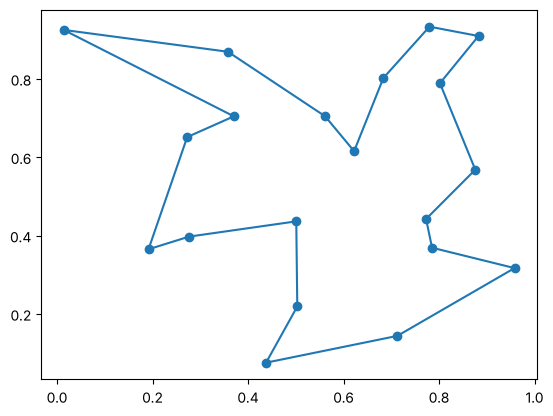

In [10]:
def simulated_annealing_tsp(tsp, tour, move=swap_cities, T0=0.3, T_end=1e-3, iters_per_city=3000):
    tour = list(tour); n = len(tour)
    max_iter = iters_per_city * n
    alpha = (T_end / T0) ** (1.0 / max_iter)          # lịch mũ: T0 -> T_end sau max_iter vòng
    cur = tour_length(tsp, tour)
    best, best_tour = cur, tour
    history, steps, evals = [cur], 0, 0
    T = T0
    for t in range(max_iter):
        i, j = sorted(np.random.choice(n, 2, replace=False))
        cand = move(tour, i, j)
        L = tour_length(tsp, cand); evals += 1
        d = L - cur
        if d < 0 or np.random.rand() < np.exp(-d / T):  # luật Metropolis
            tour, cur = cand, L; steps += 1
            if cur < best: best, best_tour = cur, tour
        history.append(cur)
        T *= alpha
    return {"tour": best_tour, "length": best, "steps": steps, "evals": evals, "history": history}

np.random.seed(4); random.seed(4)
t_start = random_tour(20)
res = simulated_annealing_tsp(tsp, t_start)
print(f"Tour ban đầu {tour_length(tsp, t_start):.3f} -> SA {res['length']:.3f}  ({res['steps']} nước đi được nhận / {res['evals']} vòng lặp)")
show_tsp(tsp, res["tour"])

**Nhận xét.** Trên cùng bài toán 20 thành phố, tour của SA dài 4.08, ngắn hơn rõ rệt so với 4.76 của steepest-ascent một lần chạy (và ngắn hơn cả lần chạy đơn tốt nhất 4.38); nhiều bước xấu được chấp nhận ở nhiệt độ cao giúp thoát các cực trị cục bộ.

## Compare Performance [2 Points]

Use runtime, scalability (number of cities), and best objective function value to compare the algorithms on boards of different sizes.  

For timing you can use the `time` package.

In [11]:
import time

t0 = time.time()
print("Do something")
t1 = time.time()

print(f"This took: {(t1-t0) * 1e3} milliseconds")

Do something
This took: 0.17881393432617188 milliseconds


### Thực nghiệm so sánh

Với mỗi kích thước $n \in \{10, 20, 30, 50\}$ ta sinh *một* bài toán TSP cố định (seed cố định) rồi chạy từng thuật toán nhiều lần từ các tour ban đầu ngẫu nhiên khác nhau. Các chỉ số: độ dài tour tốt nhất và trung bình tìm được, **mức cải thiện tương đối** so với tour ban đầu $\left(1 - L_{\text{cuối}}/L_{\text{đầu}}\right)$, số lần đánh giá và thời gian chạy trung bình. (Số lần chạy được giảm ở $n$ lớn để notebook chạy nhanh.)

In [12]:
import time

def compare(sizes=(10, 20, 30, 50), seed=2026):
    algos = {
        "Steepest asc.":            lambda tsp, t: steepest_ascent_tsp(tsp, t),
        "Steepest + Restart (10)":  lambda tsp, t: random_restart_tsp(tsp, steepest_ascent_tsp, 10),
        "Stochastic HC (mọi nước)": lambda tsp, t: stochastic_hill_climbing_tsp(tsp, t),
        "First-choice HC":          lambda tsp, t: first_choice_tsp(tsp, t),
        "Simulated Annealing":      lambda tsp, t: simulated_annealing_tsp(tsp, t),
    }
    runs = {10: 10, 20: 8, 30: 5, 50: 3}
    rows, store = [], {}
    for n in sizes:
        np.random.seed(seed + n); random.seed(seed + n)
        tsp_n = random_tsp(n)
        for name, algo in algos.items():
            k = 3 if "Restart" in name and n >= 30 else runs[n]
            L_end, L_start, evals, secs, histories = [], [], [], [], []
            for r in range(k):
                np.random.seed(r); random.seed(r)
                t_init = random_tour(n)
                t0 = time.perf_counter(); res = algo(tsp_n, t_init); secs.append(time.perf_counter() - t0)
                L_start.append(tour_length(tsp_n, t_init)); L_end.append(res["length"]); evals.append(res["evals"])
                histories.append(res["history"])
                if r == 0: first_init, first_res = t_init, res   # lưu lần chạy đầu để vẽ tour trước/sau
            store[(n, name)] = {"tsp": tsp_n, "init": first_init, "res": first_res, "hist": histories[0]}  # cùng một lần chạy
            rows.append({"Thuật toán": name, "n": n, "Số lần chạy": k,
                         "Tour tốt nhất": min(L_end), "Tour trung bình": np.mean(L_end),
                         "Cải thiện TB so với ban đầu (%)": 100 * np.mean(1 - np.array(L_end) / np.array(L_start)),
                         "Số lần đánh giá TB": np.mean(evals), "Thời gian TB (ms)": 1e3 * np.mean(secs)})
    return pd.DataFrame(rows), store

tsp_table, tsp_store = compare()
with pd.option_context("display.precision", 3):   # hiển thị 3 chữ số thập phân cho bảng này
    display(tsp_table.round({"Tour tốt nhất": 3, "Tour trung bình": 3, "Cải thiện TB so với ban đầu (%)": 1,
                             "Số lần đánh giá TB": 0, "Thời gian TB (ms)": 1}))

,Thuật toán,n,Số lần chạy,Tour tốt nhất,Tour trung bình,Cải thiện TB so với ban đầu (%),Số lần đánh giá TB,Thời gian TB (ms)
0,Steepest asc.,10,10,2.964,3.030,36.8,288.0,0.7
1,Steepest + Restart (10),10,10,2.964,2.964,38.1,2907.0,8.9
2,Stochastic HC (mọi nước),10,10,2.964,3.093,35.7,585.0,1.5
3,First-choice HC,10,10,2.964,2.964,38.1,377.0,5.5
4,Simulated Annealing,10,10,2.964,2.964,38.1,30000.0,780.4
5,Steepest asc.,20,8,4.586,4.765,50.2,2612.0,15.4
6,Steepest + Restart (10),20,8,4.148,4.254,55.5,25864.0,150.0
7,Stochastic HC (mọi nước),20,8,4.206,4.535,52.6,6484.0,54.0
8,First-choice HC,20,8,4.199,4.522,52.7,2297.0,55.5
9,Simulated Annealing,20,8,4.089,4.186,56.2,60000.0,2000.0


**Trực quan hóa:** (a) tour ngẫu nhiên ban đầu và tour sau SA của *cùng một lần chạy* (lần chạy đầu tiên, $n=30$), (b) đường hội tụ của các thuật toán ($n=30$, một lần chạy), (c) thời gian chạy theo $n$ (log-log).

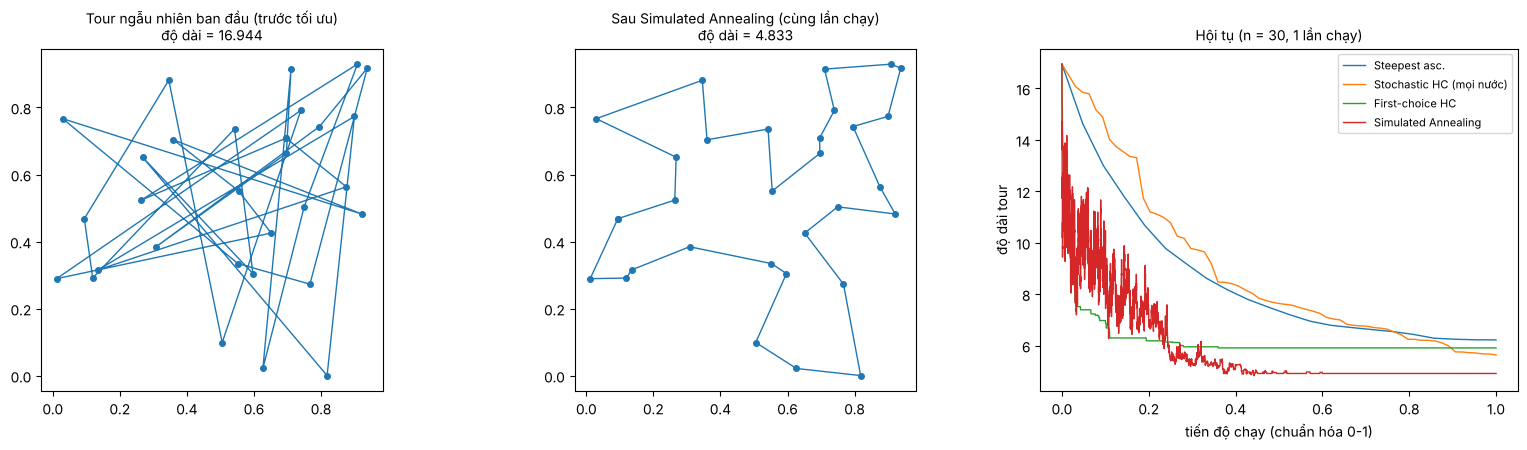

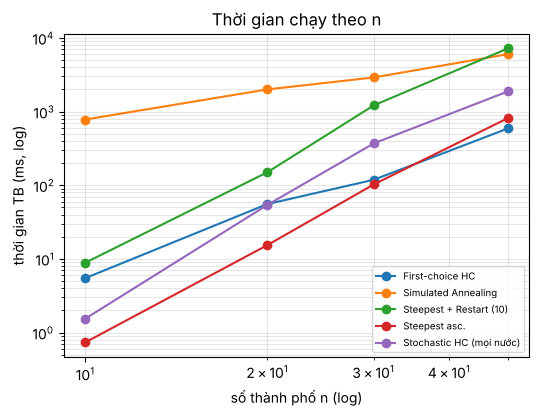

In [13]:
n_show = 30
tsp_n = tsp_store[(n_show, "Simulated Annealing")]["tsp"]
t_rand = tsp_store[(n_show, "Simulated Annealing")]["init"]      # tour xuất phát của CHÍNH lần chạy SA được vẽ

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, (title, tour) in zip(ax[:2], [("Tour ngẫu nhiên ban đầu (trước tối ưu)", t_rand),
                                    ("Sau Simulated Annealing (cùng lần chạy)", tsp_store[(n_show, "Simulated Annealing")]["res"]["tour"])]):
    pos = tsp_n["pos"].reindex(tour + [tour[0]])
    a.plot(pos["x"], pos["y"], "-o", ms=4, lw=1)
    a.set_title(f"{title}\nđộ dài = {tour_length(tsp_n, tour):.3f}", fontsize=10); a.set_aspect("equal")

for name in ["Steepest asc.", "Stochastic HC (mọi nước)", "First-choice HC", "Simulated Annealing"]:
    h = tsp_store[(n_show, name)]["hist"]
    ax[2].plot(np.linspace(0, 1, len(h)), h, label=name, lw=1)      # trục x chuẩn hóa vì mỗi thuật toán có số "bước" khác nhau
ax[2].set_xlabel("tiến độ chạy (chuẩn hóa 0-1)"); ax[2].set_ylabel("độ dài tour"); ax[2].set_title(f"Hội tụ (n = {n_show}, 1 lần chạy)", fontsize=10); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4.2))
for name, g in tsp_table.groupby("Thuật toán"):
    plt.loglog(g["n"], g["Thời gian TB (ms)"], "o-", label=name)
plt.xlabel("số thành phố n (log)"); plt.ylabel("thời gian TB (ms, log)"); plt.title("Thời gian chạy theo n"); plt.legend(fontsize=7); plt.grid(True, which="both", alpha=0.3)
plt.show()

**Nhận xét.**

* *Chất lượng:* simulated annealing cho tour ngắn nhất ở mọi kích thước (ở $n=10$ mọi thuật toán cùng đạt 2.96) và khoảng cách với các thuật toán leo đồi tăng theo $n$ (ở $n=50$ SA tốt hơn rõ rệt). Steepest + restart cải thiện đáng kể so với một lần chạy nhưng vẫn kém SA khi $n$ lớn, vì số cực trị cục bộ tăng rất nhanh theo $n$.
* *Chi phí:* các thuật toán duyệt toàn bộ lân cận (steepest, stochastic) tốn $O(n^2)$ đánh giá mỗi bước, mỗi đánh giá $O(n)$ nên thời gian tăng rất nhanh theo $n$ (đồ thị log-log dốc nhất); first-choice rẻ hơn nhiều nhưng bị giới hạn bởi ngưỡng dừng; SA có ngân sách cố định `3000·n` vòng lặp và thời gian mỗi vòng lặp bị chi phối bởi các chi phí cố định (sinh số ngẫu nhiên, sao chép tour) nên tăng chậm nhất theo $n$ (độ dốc khoảng 1.25 trong đồ thị log-log), dù ở $n$ nhỏ nó lại chậm nhất vì phải chạy đủ ngân sách.
* *Mức cải thiện tương đối so với tour ban đầu* của mọi thuật toán đều lớn (hàng chục %), vì tour ngẫu nhiên rất tệ; so sánh có ý nghĩa nhất là cột *Tour tốt nhất/trung bình*.

### Toán tử lân cận 2-opt so với hoán đổi

Với hai thành phố cách xa nhau trong tour, *hoán đổi* thay đổi tới 4 cạnh và dễ làm tour xấu đi; *2-opt* (đảo ngược đoạn giữa $i$ và $j$) chỉ thay đúng 2 cạnh nên giữ được phần lớn cấu trúc tour tốt và khử trực tiếp các cạnh cắt nhau. Ta so sánh hai toán tử trên cùng một bài toán $n=30$ với first-choice HC và SA.

In [14]:
np.random.seed(2026 + 30); random.seed(2026 + 30)
tsp30 = random_tsp(30)
rows = []
for opname, mv in [("Hoán đổi (swap)", swap_cities), ("2-opt", reverse_segment)]:
    for algo_name, algo in [("First-choice HC", lambda t, s: first_choice_tsp(t, s, move=mv)),
                            ("Simulated Annealing", lambda t, s: simulated_annealing_tsp(t, s, move=mv))]:
        L = []; secs = []
        for r in range(5):
            np.random.seed(r); random.seed(r)
            t0 = time.perf_counter(); res = algo(tsp30, random_tour(30)); secs.append(time.perf_counter() - t0); L.append(res["length"])
        rows.append({"Toán tử": opname, "Thuật toán": algo_name, "Tour tốt nhất": min(L), "Tour trung bình": np.mean(L), "Thời gian TB (s)": np.mean(secs)})
op_table = pd.DataFrame(rows).round(3)
with pd.option_context("display.precision", 3):
    display(op_table)

,Toán tử,Thuật toán,Tour tốt nhất,Tour trung bình,Thời gian TB (s)
0,Hoán đổi (swap),First-choice HC,5.466,5.795,0.173
1,Hoán đổi (swap),Simulated Annealing,4.833,4.993,2.905
2,2-opt,First-choice HC,4.833,4.942,0.144
3,2-opt,Simulated Annealing,4.825,4.841,3.688


**Nhận xét.** Với 2-opt, cả first-choice và SA đều cho tour ngắn hơn *và* ổn định hơn (độ lệch giữa tour tốt nhất và trung bình nhỏ) so với hoán đổi, vì lân cận 2-opt mang tính "cục bộ" hơn: thay đổi nhỏ trong cấu trúc tour dẫn đến thay đổi nhỏ về độ dài, nên không gian tìm kiếm trơn hơn và ít cực trị cục bộ giả hơn. Số lân cận cũng tương đương ($n(n-1)/2$) nên chi phí đánh giá mỗi bước không đổi.

## Bonus: Genetic Algorithm [+1 Point]

Thuật toán di truyền (GA) – phần mở rộng (bonus). Quần thể 100 tour; chọn lọc theo giải đấu (tournament, k = 3); lai ghép thứ tự *Order Crossover (OX)* (giữ nguyên một đoạn của bố, điền các thành phố còn lại theo thứ tự xuất hiện ở mẹ để luôn nhận được hoán vị hợp lệ); đột biến bằng đảo đoạn với xác suất 0.2; giữ lại 2 cá thể tốt nhất (elitism).

GA (n = 30): tour = 5.141 trong 2.5 s;  SA ở bảng so sánh (n = 30): tốt nhất 4.833, trung bình 4.993


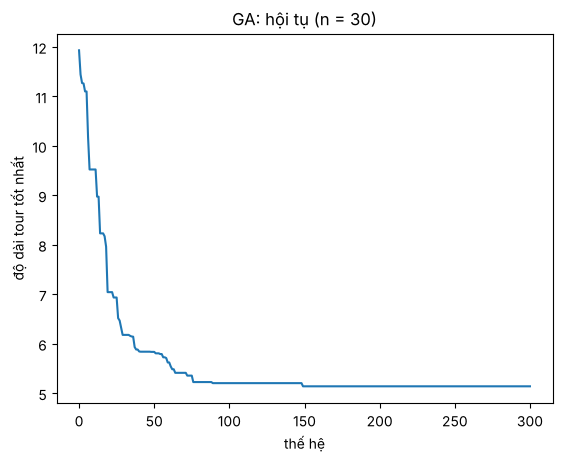

In [15]:
def order_crossover(p1, p2):
    n = len(p1)
    a, b = sorted(np.random.choice(n, 2, replace=False))
    child = [None] * n
    child[a:b + 1] = p1[a:b + 1]                       # giữ đoạn [a, b] của bố
    rest = [c for c in p2 if c not in set(p1[a:b + 1])]  # phần còn lại theo thứ tự của mẹ
    k = 0
    for i in list(range(0, a)) + list(range(b + 1, n)):
        child[i] = rest[k]; k += 1
    return child

def genetic_algorithm_tsp(tsp, pop_size=100, generations=300, p_mut=0.2, k=3, elite=2):
    n = len(tsp["dist"])
    pop = [random_tour(n) for _ in range(pop_size)]
    fit = [tour_length(tsp, t) for t in pop]
    history = [min(fit)]
    for g in range(generations):
        order = np.argsort(fit)
        new_pop = [pop[i] for i in order[:elite]]       # elitism
        while len(new_pop) < pop_size:
            parents = []
            for _ in range(2):                          # chọn lọc giải đấu
                cand = np.random.choice(pop_size, k, replace=False)
                parents.append(pop[min(cand, key=lambda i: fit[i])])
            child = order_crossover(*parents)
            if np.random.rand() < p_mut:                # đột biến: đảo đoạn
                i, j = sorted(np.random.choice(n, 2, replace=False))
                child = reverse_segment(child, i, j)
            new_pop.append(child)
        pop = new_pop
        fit = [tour_length(tsp, t) for t in pop]
        history.append(min(fit))
    best = int(np.argmin(fit))
    return {"tour": pop[best], "length": fit[best], "history": history}

np.random.seed(5); random.seed(5)
t0 = time.perf_counter(); ga = genetic_algorithm_tsp(tsp30); t_ga = time.perf_counter() - t0
sa30 = tsp_table[(tsp_table["n"] == 30) & (tsp_table["Thuật toán"] == "Simulated Annealing")].iloc[0]
print(f"GA (n = 30): tour = {ga['length']:.3f} trong {t_ga:.1f} s;  "
      f"SA ở bảng so sánh (n = 30): tốt nhất {sa30['Tour tốt nhất']:.3f}, trung bình {sa30['Tour trung bình']:.3f}")
plt.plot(ga["history"]); plt.xlabel("thế hệ"); plt.ylabel("độ dài tour tốt nhất"); plt.title("GA: hội tụ (n = 30)"); plt.show()

**Nhận xét.** GA hội tụ nhanh ở những thế hệ đầu rồi chậm dần; với tham số mặc định GA cho tour 5.14, kém SA một chút (SA trong bảng so sánh: tốt nhất 4.83, trung bình 4.99) nhưng tốt hơn các thuật toán leo đồi một lần chạy (5.79–6.18), với số lần đánh giá cùng bậc (30 000 lần tính độ dài tour so với 90 000 vòng lặp của SA ở $n=30$). GA nhạy với các tham số (kích thước quần thể, tỉ lệ đột biến, số thế hệ).